# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :Yoga Yudistira
- NIM   :241011401267
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [17]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42    # 2 digit terakhir NIM (jika 00, gunakan 100)

In [18]:
# Fungsi train_test_split (implementasi sendiri dengan NumPy)
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi train dan test secara acak (hasil dapat diulang
    karena memakai random_state)."""
    rng = np.random.RandomState(random_state)
    n = len(X)
    indices = rng.permutation(n)                 # urutan acak indeks data
    n_test = int(round(n * test_size))           # jumlah data testing
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [19]:
# Model & metrik dasar (implementasi sendiri dengan NumPy, mengikuti materi)

class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                        # tambah kolom bias (1)
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)"""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.losses_ = []
        for _ in range(self.n_iterations):
            error = self.intercept_ + X @ self.coef_ - y
            self.losses_.append(np.mean(error ** 2))          # catat MSE tiap iterasi
            self.intercept_ -= self.learning_rate * 2 * np.mean(error)
            self.coef_ -= self.learning_rate * 2 * (X.T @ error) / n
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))           # clip agar tidak overflow


class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)"""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.losses_ = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            self.losses_.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            error = p - y
            self.intercept_ -= self.learning_rate * np.mean(error)
            self.coef_ -= self.learning_rate * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred):
    """Hasil: [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


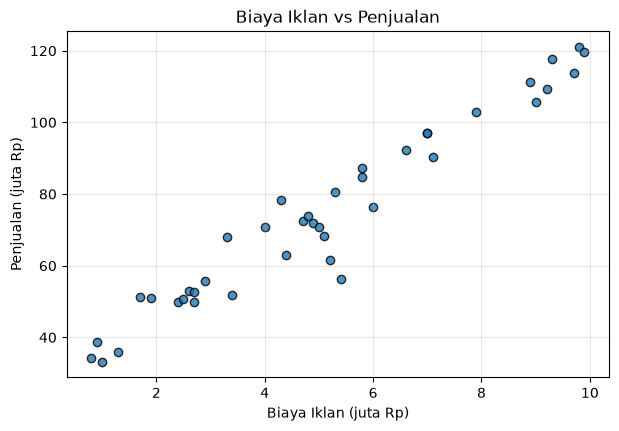

In [20]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')
print(df_ads.head())
print('\nJumlah baris data:', len(df_ads))

X = df_ads[['BiayaIklan']].values      # 2 dimensi (n, 1)
y = df_ads['Penjualan'].values         # 1 dimensi (n,)
print('Shape X:', X.shape, '| Shape y:', y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color='tab:blue', edgecolor='k', alpha=0.8)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [21]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [22]:
# Jawaban A3
lin = LinearRegression().fit(X_train, y_train)
b_ne, m_ne = lin.intercept_, lin.coef_[0]
print(f'Intercept (b)  : {b_ne:.4f}')
print(f'Koefisien (m)  : {m_ne:.4f}')
print(f'Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * BiayaIklan')

Intercept (b)  : 26.3450
Koefisien (m)  : 9.3631
Persamaan      : y_hat = 26.3450 + 9.3631 * BiayaIklan


**Jawaban A3 (interpretasi):**

Persamaan regresi hasil Normal Equation adalah ŷ = 26.345 + 9.363·X.

Koefisien m = 9.363 berarti setiap kenaikan biaya iklan sebesar 1 juta Rp diikuti kenaikan rata-rata penjualan sebesar sekitar **9.36 juta Rp** per bulan. Intercept b = 26.35 juta Rp adalah perkiraan penjualan ketika biaya iklan 0, yaitu penjualan "dasar" yang tetap terjadi tanpa iklan (nilai ini hanya perkiraan karena data terkecil sudah di sekitar 0.8 juta).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [23]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

pred_train = lin.predict(X_train)
pred_test = lin.predict(X_test)

eval_table = pd.DataFrame({
    'Training': [mae(y_train, pred_train), mse(y_train, pred_train), rmse(y_train, pred_train), r2_score(y_train, pred_train)],
    'Testing' : [mae(y_test, pred_test),   mse(y_test, pred_test),   rmse(y_test, pred_test),   r2_score(y_test, pred_test)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
print(eval_table.round(4))
print(f'\nSebagai pembanding: rata-rata Penjualan data testing = {y_test.mean():.2f}, simpangan baku = {y_test.std():.2f}')

      Training  Testing
MAE     4.1155   6.5743
MSE    31.9597  56.3244
RMSE    5.6533   7.5050
R2      0.9554   0.8135

Sebagai pembanding: rata-rata Penjualan data testing = 76.26, simpangan baku = 17.38


**Jawaban A4 (analisis):**

- **RMSE** pada data testing = 7.50 juta Rp (training = 5.65). Artinya, rata-rata prediksi penjualan model meleset sekitar 7.5 juta Rp dari nilai sebenarnya. Dibandingkan dengan rata-rata penjualan data testing (76.3 juta Rp), kesalahan ini relatif kecil.
- **R²** training = 0.955 dan testing = 0.814. Artinya, sekitar 81.4% variasi penjualan pada data testing dapat dijelaskan oleh biaya iklan.
- Kesimpulan: model ini **cukup baik** untuk memprediksi penjualan dari biaya iklan. R² testing sedikit lebih rendah daripada training, wajar karena model dibentuk dari data training dan data testing hanya 8 titik, jadi nilainya mudah berubah mengikuti pembagian data. Sisa variasi yang belum terjelaskan kemungkinan berasal dari faktor lain di luar iklan (musim, harga, stok, dsb.).

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

c:\Users\yogay\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\yogay\AppData\Local\Temp\ipykernel_1144\4266231406.py:27: RuntimeWarning: overflow encountered in square
  self.losses_.append(np.mean(error ** 2))          # catat MSE tiap iterasi
C:\Users\yogay\AppData\Local\Temp\ipykernel_1144\4266231406.py:29: RuntimeWarning: overflow encountered in matmul
  self.coef_ -= self.learning_rate * 2 * (X.T @ error) / n
C:\Users\yogay\AppData\Local\Temp\ipykernel_1144\4266231406.py:29: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * 2 * (X.T @ error) / n


         Metode  Intercept  Koefisien  MSE akhir (train)
Normal Equation    26.3450     9.3631            31.9597
  GD (lr=0.001)    23.8548     9.7426            33.4076
   GD (lr=0.02)    26.3450     9.3631            31.9597
    GD (lr=0.1)        NaN        NaN                NaN

lr=0.1: loss menjadi inf/NaN mulai iterasi ke-199


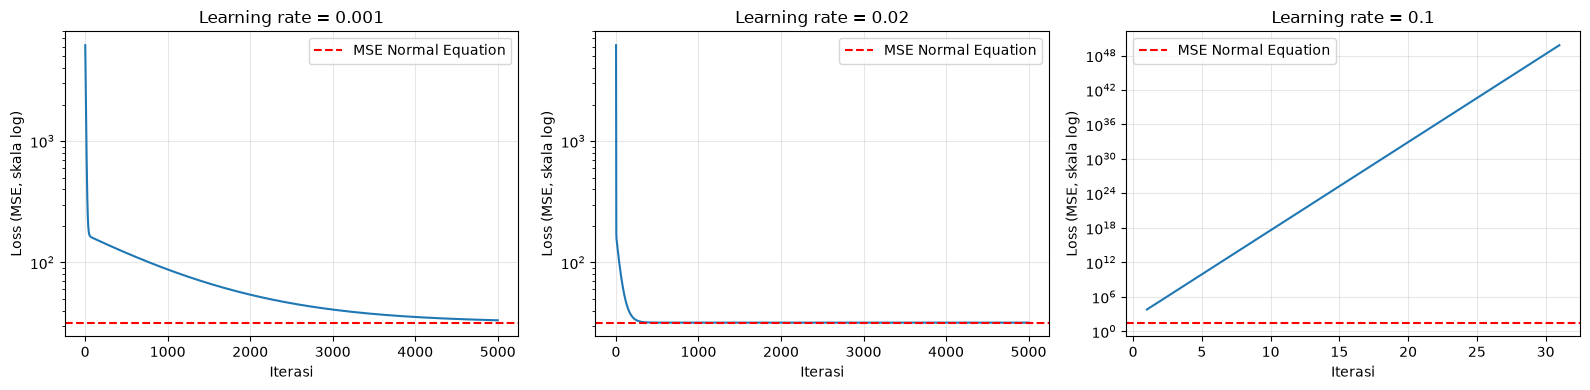

In [24]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
for lr_ in learning_rates:
    # peringatan overflow (jika muncul) sengaja tidak disembunyikan: itu bagian dari hasil eksperimen
    gd_models[lr_] = LinearRegressionGD(learning_rate=lr_, n_iterations=5000).fit(X_train, y_train)

rows = [{'Metode': 'Normal Equation', 'Intercept': b_ne, 'Koefisien': m_ne, 'MSE akhir (train)': mse(y_train, pred_train)}]
for lr_, g in gd_models.items():
    rows.append({'Metode': f'GD (lr={lr_})', 'Intercept': g.intercept_, 'Koefisien': g.coef_[0], 'MSE akhir (train)': g.losses_[-1]})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# iterasi pertama saat loss menjadi tak hingga / NaN (jika ada)
for lr_, g in gd_models.items():
    bad = np.where(~np.isfinite(g.losses_))[0]
    if len(bad) > 0:
        print(f'\nlr={lr_}: loss menjadi inf/NaN mulai iterasi ke-{bad[0] + 1}')

# grafik loss vs iterasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lr_ in zip(axes, learning_rates):
    losses = np.array(gd_models[lr_].losses_, dtype=float)
    finite = np.isfinite(losses) & (losses < 1e50)    # loss yang sudah meledak tidak digambar
    ax.plot(np.arange(1, len(losses) + 1)[finite], losses[finite])
    ax.axhline(mse(y_train, pred_train), color='red', linestyle='--', label='MSE Normal Equation')
    ax.set_yscale('log')
    ax.set_title(f'Learning rate = {lr_}')
    ax.set_xlabel('Iterasi')
    ax.set_ylabel('Loss (MSE, skala log)')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Hasil Normal Equation: b = 26.3450, m = 9.3631.

| Learning rate | Intercept | Koefisien | Keterangan |
|---|---|---|---|
| 0.001 | 23.8548 | 9.7426 | belum konvergen (terlalu lambat) |
| 0.02 | 26.3450 | 9.3631 | konvergen, sama dengan Normal Equation |
| 0.1 | NaN | NaN | divergen |

- **lr = 0.001 (terlalu lambat):** langkah tiap iterasi sangat kecil sehingga setelah 5000 iterasi parameter masih jauh dari solusi (intercept 23.85 vs 26.35, koefisien 9.743 vs 9.363) dan MSE akhirnya (33.41) masih di atas MSE Normal Equation (31.96). Loss turun, tetapi butuh iterasi jauh lebih banyak.
- **lr = 0.02 (pas):** loss turun cepat lalu mendatar tepat di MSE Normal Equation, dan parameternya sama dengan hasil Normal Equation sampai beberapa angka desimal. Inilah learning rate yang sesuai untuk data ini.
- **lr = 0.1 (divergen):** langkah terlalu besar sehingga tiap update melompati titik minimum dan mendarat di sisi seberang dengan kesalahan yang lebih besar. Kesalahan ini membesar berlipat kali setiap iterasi, loss meledak (menjadi inf mulai iterasi ke-199) lalu berubah menjadi NaN, sehingga parameter akhir NaN. Hal ini terjadi karena fitur `BiayaIklan` belum diskalakan (nilainya sampai 9.9), sehingga gradiennya besar dan batas learning rate yang aman menjadi kecil.
- **`RuntimeWarning: overflow`** berarti angka hasil perhitungan sudah melebihi nilai terbesar yang dapat disimpan float64 (sekitar 10³⁰⁸). Ini adalah tanda langsung bahwa gradient descent divergen, bukan bug pada kode.

Pelajaran: learning rate harus dipilih dengan hati-hati (atau fitur diskalakan dulu), dan grafik loss vs iterasi selalu perlu dilihat untuk memastikan training berjalan benar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

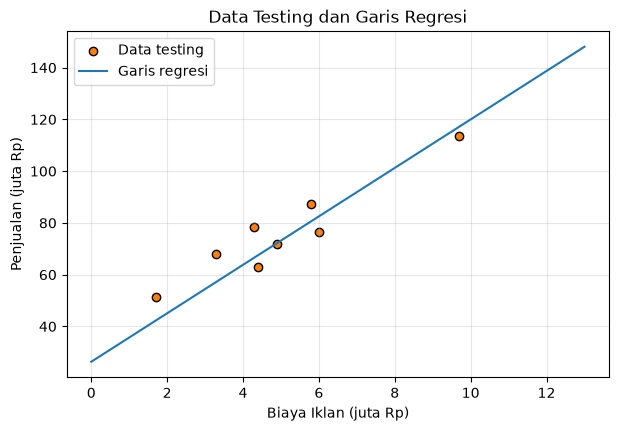

 BiayaIklan (juta)  Prediksi Penjualan (juta)
               4.5                      68.48
               7.0                      91.89
              12.0                     138.70

Rentang BiayaIklan pada data: 0.8 sampai 9.9 juta


In [25]:
# Jawaban A6
# 1. scatter data testing + garis regresi (Normal Equation)
garis_x = np.linspace(0, 13, 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color='tab:orange', edgecolor='k', label='Data testing')
plt.plot(garis_x, lin.predict(garis_x), color='tab:blue', label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. prediksi untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin.predict(biaya_baru)
print(pd.DataFrame({'BiayaIklan (juta)': biaya_baru.ravel(), 'Prediksi Penjualan (juta)': pred_baru.round(2)}).to_string(index=False))
print(f'\nRentang BiayaIklan pada data: {X.min():.1f} sampai {X.max():.1f} juta')

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4.5 juta → **68.48 juta Rp**, 7 juta → **91.89 juta Rp**, dan 12 juta → **138.70 juta Rp**.

Prediksi untuk 4.5 dan 7 juta berada di dalam rentang data (0.8 – 9.9 juta), sehingga cukup bisa dipercaya karena model dibangun dari data di daerah tersebut. Prediksi untuk **12 juta adalah ekstrapolasi** (di atas biaya iklan terbesar pada data, 9.9 juta) dan kurang bisa dipercaya. Model hanya diuji pada rentang yang ada datanya, dan garis lurus mengasumsikan hubungan tetap linear selamanya. Pada kenyataannya efek iklan biasanya menurun (*diminishing returns*) saat biaya sudah besar, pasar bisa jenuh, atau ada batas kapasitas produksi. Karena itu 138.7 juta Rp sebaiknya dianggap perkiraan kasar, bukan angka yang pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email per kelas:
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64

Shape Xe: (60, 2) | Shape ye: (60,)


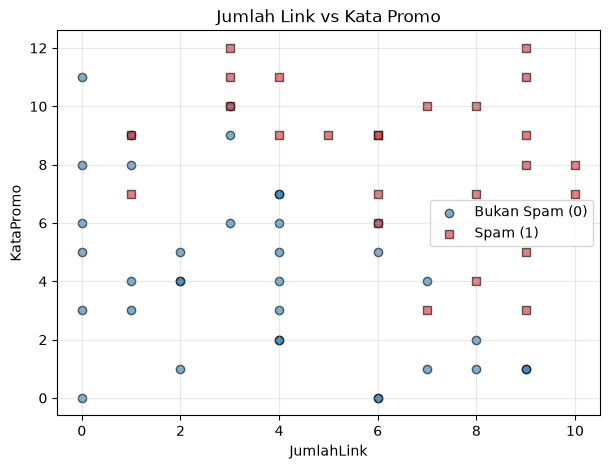

In [26]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print(df_email.head())
print('\nJumlah email per kelas:')
print(df_email['Spam'].value_counts().rename({0: 'Bukan Spam (0)', 1: 'Spam (1)'}))

Xe = df_email[['JumlahLink', 'KataPromo']].values
ye = df_email['Spam'].values
print('\nShape Xe:', Xe.shape, '| Shape ye:', ye.shape)

plt.figure(figsize=(7, 5))
plt.scatter(Xe[ye == 0, 0], Xe[ye == 0, 1], color='tab:blue', edgecolor='k', alpha=0.6, label='Bukan Spam (0)')
plt.scatter(Xe[ye == 1, 0], Xe[ye == 1, 1], color='tab:red', marker='s', edgecolor='k', alpha=0.6, label='Spam (1)')
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Intercept (b) : -9.1327
m1 (JumlahLink): 0.8080
m2 (KataPromo) : 0.7900
P(Spam) = sigmoid(-9.1327 + 0.8080 * JumlahLink + 0.7900 * KataPromo)


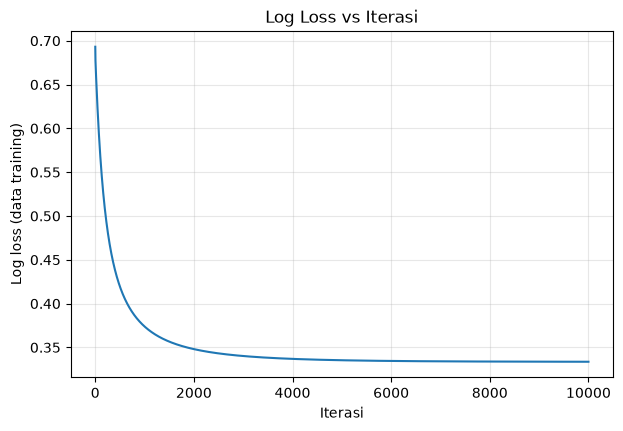

Loss awal: 0.6931 | iterasi 1000: 0.3739 | iterasi 5000: 0.3354 | akhir: 0.3336


In [27]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.25, random_state=RANDOM_STATE)
print('Xe_train:', Xe_train.shape, '| Xe_test:', Xe_test.shape)

clf = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)
b0, m1, m2 = clf.intercept_, clf.coef_[0], clf.coef_[1]
print(f'Intercept (b) : {b0:.4f}')
print(f'm1 (JumlahLink): {m1:.4f}')
print(f'm2 (KataPromo) : {m2:.4f}')
print(f'P(Spam) = sigmoid({b0:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)')

plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(clf.losses_) + 1), clf.losses_)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log loss (data training)')
plt.grid(alpha=0.3)
plt.show()
print(f'Loss awal: {clf.losses_[0]:.4f} | iterasi 1000: {clf.losses_[999]:.4f} | iterasi 5000: {clf.losses_[4999]:.4f} | akhir: {clf.losses_[-1]:.4f}')

**Jawaban B2 (analisis):**

Persamaan hasil training:

$$P(\text{Spam}) = \sigma(-9.133 + 0.808 \cdot \text{JumlahLink} + 0.790 \cdot \text{KataPromo})$$

Kedua koefisien bernilai positif, artinya semakin banyak link dan semakin banyak kata promosi dalam email, semakin besar kemungkinan email tersebut Spam. Grafik log loss turun tajam di awal (dari 0.693 yaitu ln 2 saat parameter masih 0, menjadi 0.374 pada iterasi ke-1000) dan berakhir pada 0.334. Perubahan loss pada ribuan iterasi terakhir sangat kecil (iterasi 5000: 0.3354, akhir: 0.3336), jadi loss **sudah turun dan cukup stabil**, dan training dapat dianggap konvergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [28]:
# Jawaban B3
def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = clf.predict(Xe_test)          # threshold default 0.5
cm = confusion_matrix(ye_test, ye_pred)
print(f'Accuracy : {accuracy_score(ye_test, ye_pred):.4f}')
print(f'Precision: {precision_score(ye_test, ye_pred):.4f}')
print(f'Recall   : {recall_score(ye_test, ye_pred):.4f}')
print(f'F1-score : {f1_score(ye_test, ye_pred):.4f}')
print('\nConfusion matrix (baris = aktual, kolom = prediksi):')
print(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'], columns=['Pred Bukan Spam', 'Pred Spam']))
tn, fp, fn, tp = cm.ravel()
print(f'\nTN={tn}, FP={fp}, FN={fn}, TP={tp}')

Accuracy : 0.9333
Precision: 0.8571
Recall   : 1.0000
F1-score : 0.9231

Confusion matrix (baris = aktual, kolom = prediksi):
                   Pred Bukan Spam  Pred Spam
Aktual Bukan Spam                8          1
Aktual Spam                      0          6

TN=8, FP=1, FN=0, TP=6


**Jawaban B3 (analisis):**

Pada data testing (15 email, threshold 0.5): accuracy = 0.933, precision = 0.857, recall = 1.000, F1 = 0.923. Confusion matrix: TN = 8, FP = 1, FN = 0, TP = 6.

- **FP (false positive):** email yang sebenarnya *bukan spam* tetapi dianggap *spam* oleh filter, sehingga email normal masuk ke folder spam. Pada hasil ini FP = 1.
- **FN (false negative):** email yang sebenarnya *spam* tetapi lolos ke inbox. Pada hasil ini FN = 0.

Menurut saya **FP lebih merugikan pengguna**. Email penting (misalnya dari dosen, kantor, atau notifikasi bank) yang masuk ke folder spam bisa tidak terbaca sehingga pengguna kehilangan informasi penting. Sebaliknya, FN hanya membuat pengguna menerima satu email spam di inbox, yang menjengkelkan tetapi mudah dihapus. Karena itu filter spam sebaiknya menjaga **precision** tetap tinggi.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-9.1327 + 0.8080 * JumlahLink) / 0.7900
                 = 11.5605 + (-1.0228) * JumlahLink


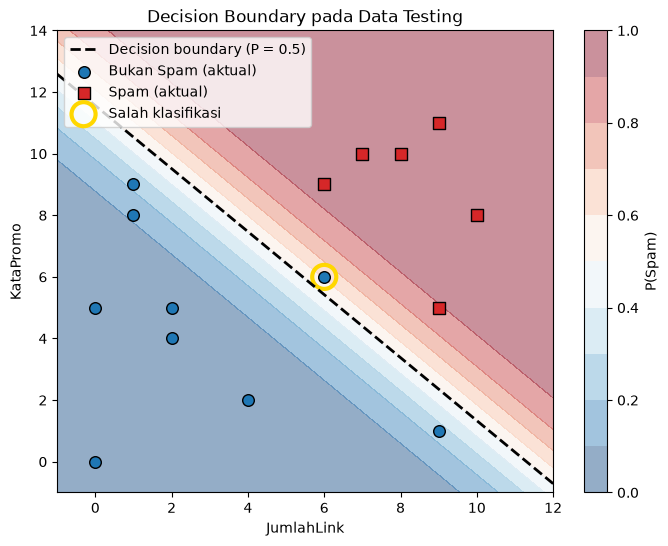

Jumlah data testing salah klasifikasi: 1 dari 15
 JumlahLink  KataPromo  Aktual  Prediksi  P(Spam)
          6          6       0         1   0.6119


In [29]:
# Jawaban B4
# 1. decision boundary: x2 = -(b + m1*x1) / m2
print(f'Decision boundary: KataPromo = -({b0:.4f} + {m1:.4f} * JumlahLink) / {m2:.4f}')
print(f'                 = {-b0 / m2:.4f} + ({-m1 / m2:.4f}) * JumlahLink')

# 2. visualisasi data testing + background probabilitas + garis boundary
xx, yy = np.meshgrid(np.linspace(-1, 12, 300), np.linspace(-1, 14, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
prob_grid = clf.predict_proba(grid).reshape(xx.shape)

salah = ye_pred != ye_test             # penanda data yang salah klasifikasi

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx, yy, prob_grid, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.45)
plt.colorbar(cs, label='P(Spam)')
x1_line = np.linspace(-1, 12, 100)
plt.plot(x1_line, -(b0 + m1 * x1_line) / m2, 'k--', linewidth=2, label='Decision boundary (P = 0.5)')
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], color='tab:blue', edgecolor='k', s=70, label='Bukan Spam (aktual)')
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], color='tab:red', marker='s', edgecolor='k', s=70, label='Spam (aktual)')
# 3. beri lingkaran besar pada data yang salah diklasifikasikan
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=300, facecolors='none', edgecolors='gold', linewidths=3, label='Salah klasifikasi')
plt.xlim(-1, 12); plt.ylim(-1, 14)
plt.title('Decision Boundary pada Data Testing')
plt.xlabel('JumlahLink'); plt.ylabel('KataPromo')
plt.legend(loc='upper left')
plt.show()

# daftar data testing yang salah diklasifikasikan
mis_df = pd.DataFrame({
    'JumlahLink': Xe_test[salah, 0], 'KataPromo': Xe_test[salah, 1],
    'Aktual': ye_test[salah], 'Prediksi': ye_pred[salah],
    'P(Spam)': clf.predict_proba(Xe_test[salah]).round(4)})
print(f'Jumlah data testing salah klasifikasi: {salah.sum()} dari {len(ye_test)}')
print(mis_df.to_string(index=False) if salah.sum() > 0 else '(tidak ada)')

**Jawaban B4 (analisis):**

Decision boundary adalah garis KataPromo = −(-9.133 + 0.808·JumlahLink) / 0.790, yaitu garis lurus dengan gradien negatif (-1.023). Titik di atas garis diprediksi Spam (P ≥ 0.5, area merah) dan titik di bawahnya Bukan Spam (area biru). Warna background memudar di sekitar garis karena di sanalah probabilitas mendekati 0.5, yaitu daerah yang paling tidak pasti.

Pada data testing terdapat **1 data yang salah diklasifikasikan** (diberi lingkaran emas pada grafik dan dirinci pada tabel di atas). Data tersebut berada dekat garis boundary, sehingga wajar model keliru: kombinasi link dan kata promonya mirip dengan kelas lawannya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [30]:
# Jawaban B5
proba_test = clf.predict_proba(Xe_test)
rows = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba_test >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(ye_test, pred_t).ravel()
    rows.append({'Threshold': t, 'TN': tn_, 'FP': fp_, 'FN': fn_, 'TP': tp_,
                 'Accuracy': accuracy_score(ye_test, pred_t),
                 'Precision': precision_score(ye_test, pred_t),
                 'Recall': recall_score(ye_test, pred_t)})
thr_table = pd.DataFrame(rows)
print(thr_table.round(4).to_string(index=False))

 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall
       0.3   8   1   0   6    0.9333     0.8571     1.0
       0.5   8   1   0   6    0.9333     0.8571     1.0
       0.7   9   0   0   6    1.0000     1.0000     1.0


**Jawaban B5 (analisis):**

| Threshold | FP | FN | Precision | Recall |
|---|---|---|---|---|
| 0.3 | 1 | 0 | 0.857 | 1.000 |
| 0.5 | 1 | 0 | 0.857 | 1.000 |
| 0.7 | 0 | 0 | 1.000 | 1.000 |

**Pengaruh threshold:** menaikkan threshold membuat model lebih "pelit" melabeli Spam, sehingga jumlah email yang diprediksi Spam berkurang. Akibatnya FP cenderung turun (precision cenderung naik), tetapi FN cenderung naik (recall cenderung turun). Menurunkan threshold berlaku sebaliknya: lebih banyak spam tertangkap (recall naik) tetapi lebih banyak email normal ikut terblokir (precision turun). Precision dan recall umumnya saling tukar (*trade-off*).

**Threshold pilihan saya: 0.7.** Berdasarkan Soal B3, FP lebih merugikan karena email normal bisa terblokir, sehingga precision diprioritaskan. Pada threshold 0.7 FP = 0 dan recall = 1.000, dibandingkan FP = 1 pada threshold 0.5. Konsekuensinya, spam yang lolos ke inbox mungkin sedikit lebih banyak, tetapi itu risiko yang lebih bisa diterima. Perlu dicatat data testing hanya 15 email, sehingga perbedaan antar threshold masih sangat dipengaruhi oleh beberapa data saja.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [31]:
# Jawaban B6
THRESHOLD = 0.7     # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
p_baru = clf.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values)
email_baru['P(Spam)'] = p_baru.round(4)
email_baru['Prediksi'] = np.where(p_baru >= THRESHOLD, 'Spam', 'Bukan Spam')
print(email_baru.to_string(index=False))

Email  JumlahLink  KataPromo  P(Spam)   Prediksi
   E1           1          2   0.0012 Bukan Spam
   E2           5          6   0.4128 Bukan Spam
   E3           9         10   0.9976       Spam
   E4           2         11   0.7637       Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena yang diprediksi adalah kategori (misalnya Spam atau Bukan Spam), bukan angka kontinu. Namanya mengandung "regression" karena di dalamnya masih ada persamaan linear z = b + m₁x₁ + m₂x₂ seperti pada regresi linear. Fungsi **sigmoid** σ(z) = 1/(1 + e⁻ᶻ) mengubah z yang bisa bernilai berapa saja menjadi angka antara 0 dan 1 yang dibaca sebagai probabilitas kelas positif. Setelah itu probabilitas dibandingkan dengan threshold (default 0.5) untuk menentukan kelas akhir.

**Jawaban C2:**
Normal equation menghitung parameter langsung dalam satu kali hitung dengan rumus θ = (XᵀX)⁻¹Xᵀy, tanpa learning rate dan tanpa iterasi. Gradient descent memperbaiki parameter sedikit demi sedikit mengikuti arah turunnya loss sampai konvergen, sehingga learning rate dan jumlah iterasi harus ditentukan. Gradient descent lebih baik dipakai ketika fitur sangat banyak atau data sangat besar, karena membalik matriks XᵀX mahal (sekitar O(d³)) dan bisa bermasalah bila matriksnya singular. Gradient descent juga dipakai pada model yang tidak punya rumus langsung, seperti Logistic Regression dan neural network. Pada data kecil dengan satu fitur seperti tugas ini, normal equation lebih sederhana dan hasilnya pasti.

**Jawaban C3:**
Model dibentuk dari data training, sehingga skor pada data tersebut tidak menunjukkan kemampuan model pada data yang belum pernah dilihat. Data testing berfungsi sebagai "ujian" untuk memperkirakan kinerja model di dunia nyata. **Overfitting** terjadi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise-nya, sehingga skor training sangat bagus tetapi skor pada data testing jauh lebih buruk. Pada tugas ini R² training = 0.955 sedangkan testing = 0.814; selisih seperti ini perlu dipantau karena selisih yang besar adalah tanda overfitting.

**Jawaban C4:**
Linear Regression memprediksi angka kontinu, sehingga wajar mengukur kesalahannya dengan jarak kuadrat antara prediksi dan nilai sebenarnya (MSE). Logistic Regression memprediksi probabilitas untuk label 0/1, sehingga loss yang cocok adalah log loss, yang berasal dari likelihood distribusi Bernoulli: loss kecil jika probabilitas untuk kelas yang benar tinggi dan sangat besar jika model yakin tetapi salah. Bila MSE dipakai bersama sigmoid, permukaan loss menjadi tidak cembung (banyak bagian datar) dan gradiennya kecil saat prediksi salah dengan yakin, sehingga training sulit dan lambat. Log loss yang dipasangkan dengan sigmoid bersifat cembung dan gradiennya sederhana (p − y).

**Jawaban C5:**
`random_state` dari tiap mahasiswa berbeda (dua digit terakhir NIM), sehingga data training dan testing yang terpilih secara acak juga berbeda. Model dilatih dari data training yang berbeda sehingga koefisiennya berbeda, dan dievaluasi pada data testing yang berbeda sehingga akurasi dan R²-nya ikut berbeda. Efeknya terasa besar karena datasetnya kecil (40 dan 60 baris): satu atau dua data yang pindah ke testing bisa mengubah hasil secara nyata. Karena itu hasil yang berbeda tidak berarti salah, selama algoritma dan alurnya benar.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [32]:
# Jawaban Bonus
# scikit-learn hanya dipakai di sel ini untuk perbandingan
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# ---- Linear Regression ----
sk_lin = SkLinearRegression().fit(X_train, y_train)
tabel_lin = pd.DataFrame({
    'Intercept': [b_ne, sk_lin.intercept_],
    'Koefisien': [m_ne, sk_lin.coef_[0]],
    'R2 testing': [r2_score(y_test, lin.predict(X_test)), r2_score(y_test, sk_lin.predict(X_test))],
}, index=['Implementasi sendiri', 'scikit-learn'])
print('=== Linear Regression ===')
print(tabel_lin.round(6))

# ---- Logistic Regression ----
sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                      # default: L2, C=1.0
sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)  # hampir tanpa regularisasi
own_long = LogisticRegression(learning_rate=0.1, n_iterations=100000).fit(Xe_train, ye_train)  # GD dilatih lebih lama

def ringkas(nama, b, w, pred):
    return {'Model': nama, 'b': b, 'm1': w[0], 'm2': w[1],
            'Accuracy (test)': accuracy_score(ye_test, pred),
            'Precision (test)': precision_score(ye_test, pred),
            'Recall (test)': recall_score(ye_test, pred)}

tabel_log = pd.DataFrame([
    ringkas('Sendiri (GD, 10.000 iter)', clf.intercept_, clf.coef_, clf.predict(Xe_test)),
    ringkas('Sendiri (GD, 100.000 iter)', own_long.intercept_, own_long.coef_, own_long.predict(Xe_test)),
    ringkas('sklearn default (C=1, L2)', sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas('sklearn C=1e10 (tanpa reg.)', sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xe_test)),
])
print('\n=== Logistic Regression ===')
print(tabel_log.round(4).to_string(index=False))

=== Linear Regression ===
                      Intercept  Koefisien  R2 testing
Implementasi sendiri  26.345036   9.363102    0.813506
scikit-learn          26.345036   9.363102    0.813506

=== Logistic Regression ===
                      Model       b     m1     m2  Accuracy (test)  Precision (test)  Recall (test)
  Sendiri (GD, 10.000 iter) -9.1327 0.8080 0.7900           0.9333            0.8571            1.0
 Sendiri (GD, 100.000 iter) -9.4402 0.8373 0.8146           0.9333            0.8571            1.0
  sklearn default (C=1, L2) -8.4288 0.7373 0.7328           0.9333            0.8571            1.0
sklearn C=1e10 (tanpa reg.) -9.4403 0.8373 0.8146           0.9333            0.8571            1.0


**Jawaban Bonus (analisis):**

**Linear Regression.** Intercept (26.3450), koefisien (9.3631), dan R² testing identik antara implementasi sendiri dan scikit-learn. Keduanya sama-sama menyelesaikan solusi kuadrat terkecil secara eksak, sehingga hasilnya harus sama.

**Logistic Regression.** Koefisien implementasi sendiri (b = -9.133, m₁ = 0.808, m₂ = 0.790) **berbeda** dengan scikit-learn default (b = -8.429, m₁ = 0.737, m₂ = 0.733). Penyebabnya:

1. **Regularisasi.** `LogisticRegression` scikit-learn secara default memakai penalti L2 dengan `C = 1.0`. Penalti ini menahan koefisien agar tidak besar, sehingga koefisiennya lebih kecil (menyusut ke 0). Implementasi sendiri tidak memakai regularisasi. Jika regularisasi dibuat hampir hilang (`C = 1e10`), hasil scikit-learn mendekati implementasi sendiri (b = -9.440, m₁ = 0.837, m₂ = 0.815).
2. **Konvergensi.** Sisa selisih kecil berasal dari gradient descent dengan 10.000 iterasi yang belum benar-benar sampai di titik minimum, sedangkan scikit-learn memakai optimizer (lbfgs) yang berjalan sampai konvergen. Terbukti ketika implementasi sendiri dilatih 100.000 iterasi, koefisiennya (b = -9.440, m₁ = 0.837, m₂ = 0.815) makin dekat dengan scikit-learn tanpa regularisasi.

Meskipun koefisiennya berbeda, accuracy, precision, dan recall pada data testing sama atau hampir sama (0.933 vs 0.933), karena perbedaan kecil pada koefisien hanya menggeser sedikit posisi decision boundary.